# Разведочный анализ данных

**Проект:** прогнозирование популярности бьюти-видео на YouTube. Команда 127, тема № 84, чекпойнт 2.

**Данные:** выгрузка сборщика `daily_collect.py` (YouTube Data API v3), последний замер 08.11.2026 09:38 UTC.
Одна строка соответствует одному видео. Колонки `views_d0`...`views_d7` содержат просмотры на день жизни ролика,
целевая переменная проекта `views_d7`.

**Запуск.** В папке с ноутбуком должны лежать `videos.xlsx` (или `videos.parquet`), `channels.parquet`
из служебных таблиц сборщика и `eda_manual_check_200.csv`. Результаты сохраняются в `results/`.

| Вопрос | Ответ |
|---|---|
| Объём | 192 623 видео, 12 184 канала. После очистки 63 486 видео, целевая переменная известна у 20 638 видео от 4 831 канала |
| Качество выгрузки | Очистку проходят 33% записей: большая часть видео пришла из обхода загрузок каналов, половина из них не про бьюти или не на английском |
| Проверка очистки | Ручная разметка 200 записей: точность 85%, полнота около 84% |
| Целевая переменная | `log1p(views_d7)`, замер в возрасте 7-8 суток. К первому дню набирается 91% итоговых просмотров, к третьему 98% |
| Что объясняет просмотры | Канал объясняет 76% разброса. Связи описания, эмодзи и хэштегов с просмотрами почти исчезают внутри канала |

## 0. Подготовка

In [1]:
import json
import re
import unicodedata
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import py3langid as langid
import seaborn as sns

warnings.filterwarnings("ignore")

RAW_XLSX = Path("videos.xlsx")
CACHE = Path("videos.parquet")
CHANNELS = Path("channels.parquet")
MANUAL = Path("eda_manual_check_200.csv")
OUT = Path("results")
OUT.mkdir(exist_ok=True)
SEED = 42

C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#9b9a96"
sns.set_theme(style="whitegrid", font_scale=0.9)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "grid.color": "#e6e5e1"})
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)


def fmt(x):
    return f"{x:,.0f}".replace(",", " ")


def rho(a, b):
    return pd.Series(np.asarray(a, float)).corr(pd.Series(np.asarray(b, float)), method="spearman")

## 1. Данные и как они собраны

Сборщик ищет видео по 39 хэштегам, затем обходит свежие загрузки каждого найденного канала. Все видео младше
восьми суток перезамеряются при каждом прогоне, из замеров строятся колонки `views_d0`...`views_d7`.

In [2]:
if CACHE.exists():
    raw = pd.read_parquet(CACHE)
else:
    raw = pd.read_excel(RAW_XLSX)
    raw.to_parquet(CACHE, index=False)
for col in ("published_at", "observed_at_latest"):
    raw[col] = pd.to_datetime(raw[col], utc=True, format="mixed").dt.tz_localize(None)
channels = pd.read_parquet(CHANNELS)
SNAPSHOT = raw.observed_at_latest.max()

print(f"видео: {fmt(len(raw))} | колонок: {raw.shape[1]} | уникальных video_id: {fmt(raw.video_id.nunique())} "
      f"| каналов: {fmt(raw.channel_id.nunique())}")
print("публикация:", raw.published_at.min(), "...", raw.published_at.max())
print("последний замер:", raw.observed_at_latest.min(), "...", raw.observed_at_latest.max())

видео: 192 623 | колонок: 44 | уникальных video_id: 192 623 | каналов: 12 184
публикация: 2026-10-25 22:49:10 ... 2026-11-08 10:35:56
последний замер: 2026-11-02 22:48:24 ... 2026-11-08 09:38:50


Дублей по `video_id` нет. Ролики опубликованы с 25 октября по 8 ноября, замеры шли со 2 по 8 ноября.

In [3]:
groups = {
    "Идентификаторы и время": ["video_id", "channel_id", "channel_title", "published_at", "observed_at_latest"],
    "Содержание ролика": ["title", "description", "tags", "duration_s", "duration", "category_id",
                          "default_language", "default_audio_language"],
    "Как видео найдено": ["found_by_tag", "beauty_category", "found_by"],
    "Статистика по дням жизни": [f"{m}_d{k}" for m in ("views", "likes", "comments") for k in range(8)],
    "Последний замер и служебное": ["views_latest", "likes_latest", "comments_latest", "n_measurements"],
}
pd.DataFrame([(g, len(c), ", ".join(c[:6]) + (" ..." if len(c) > 6 else "")) for g, c in groups.items()],
             columns=["группа", "колонок", "колонки"])

,группа,колонок,колонки
0,Идентификаторы и время,5,"video_id, channel_id, channel_title, published_at, observed_at_latest"
1,Содержание ролика,8,"title, description, tags, duration_s, duration, category_id ..."
2,Как видео найдено,3,"found_by_tag, beauty_category, found_by"
3,Статистика по дням жизни,24,"views_d0, views_d1, views_d2, views_d3, views_d4, views_d5 ..."
4,Последний замер и служебное,4,"views_latest, likes_latest, comments_latest, n_measurements"


### Описательные статистики

In [4]:
raw.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
video_id,192623,192623,YhJaWfxQ4Fc,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,192623,175111,unknown,281,NaN,NaN,NaN,NaN,NaN,NaN,NaN
channel_title,192623,12180,Firstpost,826,NaN,NaN,NaN,NaN,NaN,NaN,NaN
published_at,192623,NaN,NaN,NaN,2026-11-03 02:14:08.031091456,2026-10-25 22:49:10,2026-10-31 15:57:50,2026-11-03 11:30:05,2026-11-05 19:08:15.500000,2026-11-08 10:35:56,NaN
duration_s,192544.0,NaN,NaN,NaN,167.3616,0.0,15.0,29.0,61.0,610467.0,2005.648159
views_latest,192619.0,NaN,NaN,NaN,13374.927531,0.0,37.0,674.0,1669.0,49962022.0,191988.401415
likes_latest,186262.0,NaN,NaN,NaN,256.519005,0.0,1.0,6.0,26.0,458961.0,3459.159233
comments_latest,188171.0,NaN,NaN,NaN,6.29267,0.0,0.0,0.0,1.0,19466.0,95.147033
observed_at_latest,192623,NaN,NaN,NaN,2026-11-07 19:22:45.156865280,2026-11-02 22:48:24,2026-11-08 09:38:50,2026-11-08 09:38:50,2026-11-08 09:38:50,2026-11-08 09:38:50,NaN
found_by_tag,192623,39,#lashes,15422,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Самый частый заголовок `unknown` встречается 281 раз. Средние просмотры в десятки раз выше медианных,
распределение сильно скошено. Длительность доходит до 610 467 секунд, такие записи разобраны в разделе об очистке.

### Расписание замеров

In [5]:
runs = raw.observed_at_latest.value_counts().sort_index()
pd.DataFrame({"прогон (UTC)": runs.index.strftime("%d.%m %H:%M"),
              "часов с прошлого прогона": (runs.index.to_series().diff().dt.total_seconds() / 3600).round(1).values,
              "видео с последним замером в прогоне": runs.values})

,прогон (UTC),часов с прошлого прогона,видео с последним замером в прогоне
0,02.11 22:48,NaN,2592
1,03.11 15:49,17.0,4816
2,04.11 14:56,23.1,7531
3,05.11 18:15,27.3,8934
4,06.11 19:21,25.1,13935
5,07.11 21:38,26.3,6505
6,08.11 09:38,12.0,148310


Прошло семь прогонов, интервал между ними менялся от 12 до 27 часов. Окно седьмого дня шириной ровно сутки,
поэтому при интервале больше 24 часов часть видео его пропускает (раздел 3).

### Откуда пришли видео

In [6]:
text_all = (raw.title.fillna("") + " " + raw.description.fillna("") + " " + raw.tags.fillna("")).str.lower()
has_tag = pd.Series([t.lower() in s for t, s in zip(raw.found_by_tag, text_all)], index=raw.index)
beauty_word = text_all.str.contains(r"nail|lash|brow|skin|makeup|perfume|fragrance|beauty|hair|lotion|serum|scent")
print(f"хэштег поиска есть в тексте у {has_tag.mean():.1%} видео")
print(f"бьюти-слова встречаются у {beauty_word[has_tag].mean():.0%} таких видео и у {beauty_word[~has_tag].mean():.0%} остальных")

хэштег поиска есть в тексте у 12.0% видео
бьюти-слова встречаются у 96% таких видео и у 45% остальных


Хэштег, по которому видео найдено, есть в тексте лишь у 12% роликов. Остальные пришли из обхода загрузок канала,
и бьюти-слова встречаются только у 45% из них. Поэтому `found_by_tag` и `beauty_category` описывают канал,
через который нашли видео, а не само видео, и без тематической и языковой очистки выводы будут не про бьюти.

## 2. Пропуски

In [7]:
na = pd.DataFrame({"пропусков": raw.isna().sum(), "доля, %": (raw.isna().mean() * 100).round(1)})
na = na[na["пропусков"] > 0].sort_values("доля, %", ascending=False)
print(f"пропущено {raw.isna().sum().sum() / raw.size:.1%} ячеек, колонок с пропусками: {len(na)} из {raw.shape[1]}")
kind = {**{c: "1. статистика по дням" for c in na.index if re.search(r"_d\d$", c)},
        "default_audio_language": "2. необязательные поля", "description": "2. необязательные поля",
        "likes_latest": "3. скрыто автором", "comments_latest": "3. скрыто автором",
        "duration_s": "4. технические", "duration": "4. технические", "views_latest": "4. технические",
        "default_language": "4. технические", "n_measurements": "4. технические"}
na["тип"] = na.index.map(kind)
na.groupby("тип").agg(колонок=("пропусков", "size"), доля_от=("доля, %", "min"), доля_до=("доля, %", "max"))

пропущено 38.4% ячеек, колонок с пропусками: 33 из 44


,колонок,доля_от,доля_до
тип,,,
1. статистика по дням,24,60.7,71.9
2. необязательные поля,2,37.8,48.5
3. скрыто автором,2,2.3,3.3
4. технические,5,0.0,0.1


Пропущено 38.4% ячеек, пропуски делятся на четыре типа.

| Тип | Колонки | Причина | Обработка |
|---|---|---|---|
| Статистика по дням (61-72%) | `views/likes/comments_d0...d7` | видео ещё не дожило до дня или было найдено позже | не заполняем, цель берём только у видео с полным горизонтом |
| Необязательные поля (38-49%) | `description`, `default_audio_language` | автор не заполнил | пустая строка, сам факт заполнения используем как признак |
| Скрыто автором (2-3%) | `likes_latest`, `comments_latest` | лайки скрыты или комментарии выключены | флаг для описания данных |
| Технические (меньше 0.1%) | `duration_s`, `views_latest` | сбой API | записи уходят в фильтре `is_live` |

### Гипотеза о пропусках в `views_d7`

Если пропуск означает, что видео ещё не прожило семи суток, то у видео без `views_d7` возраст на момент последнего
замера должен быть меньше.

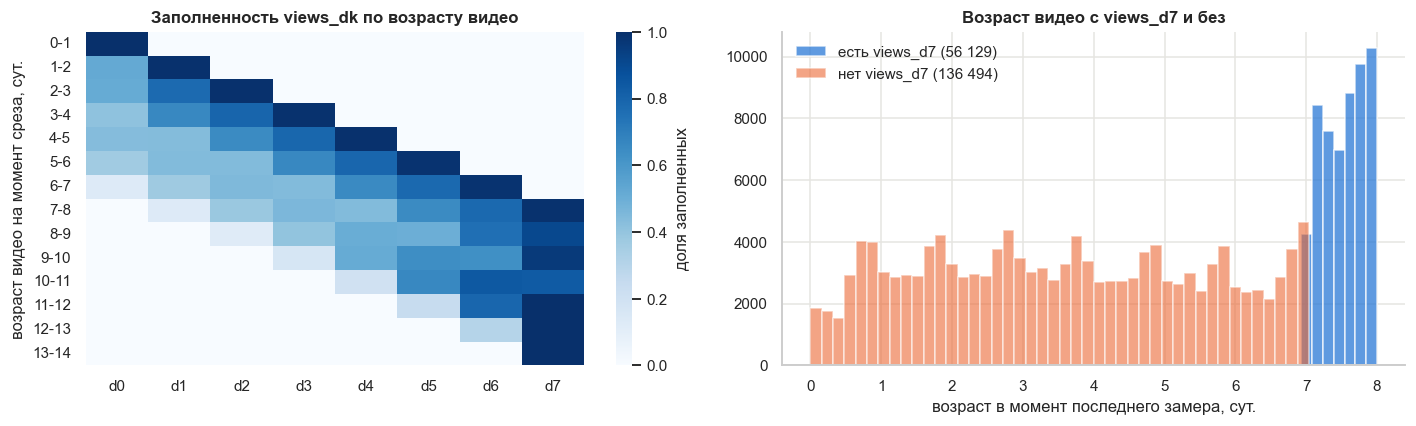

,count,mean,std,min,25%,50%,75%,max
views_d7,,,,,,,,
есть views_d7,56129.0,7.53,0.30,0.36,7.26,7.56,7.79,8.0
нет views_d7,136494.0,3.56,1.98,-0.04,1.85,3.51,5.24,8.0


In [8]:
raw["age_now_d"] = (SNAPSHOT - raw.published_at).dt.total_seconds() / 86400
raw["age_last_obs_d"] = (raw.observed_at_latest - raw.published_at).dt.total_seconds() / 86400
cov = raw[[f"views_d{k}" for k in range(8)]].notna().groupby(pd.cut(raw.age_now_d, range(0, 15), right=False),
                                                             observed=False).mean()
h = raw.views_d7.notna()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(cov, ax=ax[0], cmap="Blues", vmin=0, vmax=1, cbar_kws={"label": "доля заполненных"},
            yticklabels=[f"{i}-{i + 1}" for i in range(14)], xticklabels=[f"d{k}" for k in range(8)])
ax[0].set_ylabel("возраст видео на момент среза, сут.")
ax[0].set_title("Заполненность views_dk по возрасту видео")
ax[1].hist(raw.loc[h, "age_last_obs_d"].clip(0, 8.5), bins=50, alpha=.75, color=C[0], label=f"есть views_d7 ({fmt(h.sum())})")
ax[1].hist(raw.loc[~h, "age_last_obs_d"].clip(0, 8.5), bins=50, alpha=.6, color=C[1], label=f"нет views_d7 ({fmt((~h).sum())})")
ax[1].set_xlabel("возраст в момент последнего замера, сут.")
ax[1].set_title("Возраст видео с views_d7 и без")
ax[1].legend(frameon=False)
plt.tight_layout()
plt.show()
raw.groupby(h.map({True: "есть views_d7", False: "нет views_d7"})).age_last_obs_d.describe().round(2)

Гипотеза подтвердилась. У видео с `views_d7` возраст сосредоточен в окне 7-8 суток (медиана 7.56, разброс 0.30),
у видео без него медиана 3.51 суток. На тепловой карте день `k` заполнен только у видео старше `k` суток.
Ранние дни заполнены частично: замер стартовал 2 ноября, и у видео, найденных уже взрослыми, ранних замеров нет.

In [9]:
pd.Series({
    "лайки скрыты": (raw.likes_latest.isna() & raw.views_latest.notna()).mean(),
    "комментарии выключены": (raw.comments_latest.isna() & raw.views_latest.notna()).mean(),
    "есть views_d7, но нет likes_d7": (raw.views_d7.notna() & raw.likes_d7.isna()).sum() / raw.views_d7.notna().sum(),
}).map("{:.1%}".format).to_frame("доля")

,доля
лайки скрыты,3.3%
комментарии выключены,2.3%
"есть views_d7, но нет likes_d7",3.5%


Флаг скрытых метрик строим по последнему замеру: у `likes_d7` пропуск ещё и структурный. В признаки модели флаг
не берём, автор может скрыть лайки уже после публикации.

## 3. Ошибочные значения и надёжность целевой переменной

In [10]:
anomalies = {
    "возраст в последнем замере < 0": raw.age_last_obs_d < 0,
    "есть views_d7 при возрасте < 7 сут.": raw.views_d7.notna() & (raw.age_last_obs_d < 7),
    "есть views_d7 при возрасте 7-8 сут. (норма)": raw.views_d7.notna() & raw.age_last_obs_d.between(7, 8),
    "старше 8 сут., но views_d7 нет": raw.views_d7.isna() & (raw.age_now_d >= 8),
}
pd.DataFrame({"видео": {k: int(v.sum()) for k, v in anomalies.items()},
              "доля, %": {k: round(100 * v.mean(), 2) for k, v in anomalies.items()}})

,видео,"доля, %"
возраст в последнем замере < 0,231,0.12
есть views_d7 при возрасте < 7 сут.,1,0.00
есть views_d7 при возрасте 7-8 сут. (норма),56128,29.14
"старше 8 сут., но views_d7 нет",2937,1.52


In [11]:
lost = raw[anomalies["старше 8 сут., но views_d7 нет"]]
print("возраст потерянных видео в последнем замере, сут.:")
print(lost.age_last_obs_d.describe(percentiles=[.1, .5, .9]).round(2).to_string())
print("\nпрогон последнего замера:")
print(lost.observed_at_latest.dt.strftime("%d.%m %H:%M").value_counts().sort_index().to_string())
neg = raw[anomalies["возраст в последнем замере < 0"]]
print(f"\nотрицательный возраст: {len(neg)} видео, из них с нулём просмотров {(neg.views_latest == 0).mean():.0%}")

возраст потерянных видео в последнем замере, сут.:
count    2937.00
mean        6.88
std         0.40
min         2.79
10%         6.89
50%         6.95
90%         6.99
max         8.00

прогон последнего замера:
observed_at_latest
02.11 22:48      19
03.11 15:49      23
04.11 14:56    1270
05.11 18:15     420
06.11 19:21    1205

отрицательный возраст: 231 видео, из них с нулём просмотров 24%


* **Отрицательный возраст, 231 видео.** Дата публикации позже времени замера: у премьер и отложенных публикаций
  YouTube переписывает дату при выходе. Исключаем флагом `bad_dates`.
* **`views_d7` при возрасте 0.36 суток, одно видео.** Та же причина. Исключается правилом «замер в возрасте 7-8 суток».
* **Потерянный седьмой день, 2 937 видео.** Последний замер был в возрасте около 6.95 суток, следующий прогон прошёл
  через 25-27 часов, и видео уже вышло из наблюдения. Сборщик нужно запускать строго раз в сутки или продлить
  `TRACK_DAYS` до 9.

прирост просмотров с d6 до d7, квантили 50/75/90%: [1.001, 1.011, 1.043]


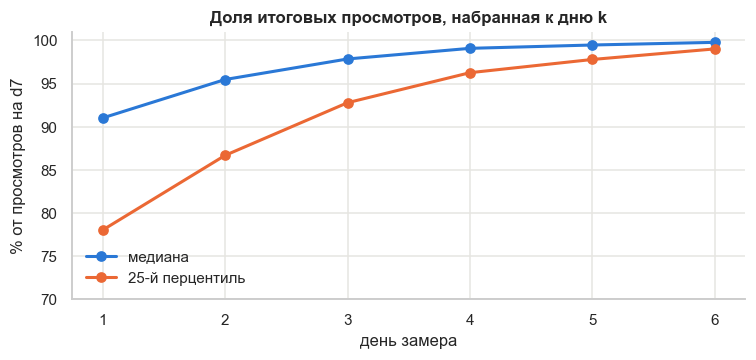

,день,видео,медианная_доля_от_d7,доля_q25,spearman_с_d7
0,1,1267,0.910,0.780,0.991
1,2,5281,0.955,0.867,0.995
2,3,9990,0.979,0.928,0.996
3,4,14253,0.991,0.963,0.998
4,5,20423,0.995,0.978,0.999
5,6,28508,0.998,0.990,1.000


In [12]:
h7 = raw[raw.views_d7.notna() & raw.age_last_obs_d.between(7, 8)]
rows = []
for k in range(1, 7):
    s = h7[h7[f"views_d{k}"].notna() & (h7.views_d7 >= 100)]
    r = (s[f"views_d{k}"] + 1) / (s.views_d7 + 1)
    rows.append({"день": k, "видео": len(s), "медианная_доля_от_d7": r.median(), "доля_q25": r.quantile(.25),
                 "spearman_с_d7": rho(s[f"views_d{k}"], s.views_d7)})
dyn = pd.DataFrame(rows)
g67 = h7.dropna(subset=["views_d6"])
print("прирост просмотров с d6 до d7, квантили 50/75/90%:",
      ((g67.views_d7 + 1) / (g67.views_d6 + 1)).quantile([.5, .75, .9]).round(3).tolist())
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(dyn["день"], dyn.медианная_доля_от_d7 * 100, marker="o", color=C[0], lw=2, label="медиана")
ax.plot(dyn["день"], dyn.доля_q25 * 100, marker="o", color=C[1], lw=2, label="25-й перцентиль")
ax.set_ylim(70, 101)
ax.set_xlabel("день замера")
ax.set_ylabel("% от просмотров на d7")
ax.set_title("Доля итоговых просмотров, набранная к дню k")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
dyn.round(3)

Фиксируем целевую переменную как просмотры в замере в возрасте от 7 до 8 суток, видео без такого замера в обучение
не входят. Допуск в сутки почти не меняет значение: с шестого по седьмой день у половины видео прирост 0.1%,
у 90% меньше 4.3%. К первому дню набирается 91% итоговых просмотров, к третьему 98%, ранговая корреляция третьего
и седьмого дня 0.996. Просмотры на третий день можно использовать как запасную цель.

## 4. Очистка

| Флаг | Правило |
|---|---|
| `is_beauty` | в заголовке, описании или тегах есть слово из бьюти-словаря |
| `is_en` | язык текста английский по `py3langid`, `default_language` английский, аудио английское или не указано |
| `is_spam` | контакты для заказа: WhatsApp, Telegram, телефон, «order now» |
| `is_live` | трансляции, нулевая или пустая длительность, больше трёх часов |
| `is_dup_title` | повтор заголовка на том же канале |
| `offtopic_yt_cat` | категория YouTube Music, Gaming, Pets, Sports, News и похожие |
| `bad_dates` | отрицательный возраст |
| `has_d7` | есть замер в возрасте 7-8 суток |

Рекламу (`is_ad`) не удаляем и оставляем признаком. Длительность не фильтруем, формат входит в признаки.

In [13]:
langid.set_languages(["en", "es", "pt", "de", "fr", "it", "nl", "pl", "ru", "uk", "tr", "id", "ms",
                      "tl", "vi", "th", "hi", "ur", "bn", "ta", "te", "ml", "si", "ar", "ko", "ja", "zh"])

BEAUTY = {
    "skincare": ["skin", "serum", "moistur", "sunscreen", "spf", "acne", "pimple", "retinol", "niacinamide",
                 "cleanser", "toner", "facial", "pore", "wrinkle", "dark spot", "dark circle", "face mask",
                 "hyperpigment", "anti aging", "antiaging", "collagen", "glass skin", "k-beauty", "kbeauty",
                 "sunblock", "glow", "eye cream", "hyaluronic", "vitamin c", "exfoliat", "blackhead", "tan remov"],
    "fragrance": ["perfume", "fragrance", "cologne", "parfum", "scent", "eau de", "edp", "edt", "oud",
                  "dupe", "sillage", "smell"],
    "body": ["bodycare", "body care", "body lotion", "body wash", "body scrub", "body butter", "body oil",
             "shower", "deodorant", "selfcare", "self care", "self-care", "lotion", "scrub", "shav", "wax",
             "everything shower", "hygiene", "exfoliat", "body mist"],
    "nails_lashes_brows": ["nail", "manicure", "pedicure", "lash", "brow", "gel polish", "polish", "acrylic",
                           "press on", "presson", "cuticle", "lamination", "mascara", "eyelash"],
    "makeup": ["makeup", "make up", "mackup", "lipstick", "lip gloss", "lipgloss", "lip liner", "lip combo",
               "lip balm", "foundation", "concealer", "eyeliner", "eyeshadow", "blush", "contour", "highlighter",
               "primer", "bronzer", "setting spray", "mua"],
    "haircare": ["hair", "shampoo", "conditioner", "curl", "scalp", "braid", "wig", "detangl", "keratin"],
    "general": ["beauty", "grwm", "get ready with me", "cosmetic", "sephora", "ulta", "routine"],
}
CAT_RX = {c: re.compile(r"(?<![a-z])(" + "|".join(re.escape(w) for w in ws) + ")", re.I) for c, ws in BEAUTY.items()}
SPAM_RX = re.compile(r"whatsapp|telegram|\+\d{1,3}[\s-]?\d{9,}|order now|dm (?:me )?for (?:price|order)|"
                     r"call now|cash on delivery|\bcod\b", re.I)
AD_RX = re.compile(r"#ad\b|#sponsored|sponsor|#partner|paid partnership|#gifted|tiktokshop|amazon find|"
                   r"use code|discount code|affiliate|commission", re.I)
LIVE_RX = re.compile(r"(?:\bis live\b|live stream|livestream|\blive now\b)", re.I)
OFFTOPIC_YT_CAT = {1, 2, 10, 15, 17, 19, 20, 25, 28, 29}
HASH_URL_RX = re.compile(r"https?://\S+|www\.\S+|[#@]\S+")


def detect_lang(title, desc):
    t = f"{title} {'' if pd.isna(desc) else str(desc)[:400]}"
    t = re.sub(r"\s+", " ", re.sub(r"[^\w\s'’.,!?-]", " ", HASH_URL_RX.sub(" ", t))).strip()
    if len(re.findall(r"[A-Za-zÀ-￿]", t)) < 8:
        return "short"
    return langid.classify(t)[0]


def add_flags(df):
    df = df.copy()
    df["lang_detected"] = [detect_lang(t, d) for t, d in zip(df.title, df.description)]
    meta_en = df.default_language.fillna("").str.lower().str.startswith("en")
    audio = df.default_audio_language.fillna("na").str.lower()
    audio_ok = audio.str.startswith("en") | audio.isin(["na", "zxx", "und"])
    text_en = df.lang_detected.eq("en") | (df.lang_detected.eq("short") & meta_en)
    df["is_en"] = text_en & audio_ok & meta_en
    text = df.title.fillna("") + " " + df.description.fillna("").str[:1500] + " " + df.tags.fillna("")
    for c, r in CAT_RX.items():
        df[f"kw_{c}"] = text.str.contains(r)
    order = ["skincare", "fragrance", "body", "nails_lashes_brows", "makeup", "haircare"]
    kw = df[[f"kw_{c}" for c in order]].to_numpy()
    own = np.zeros(len(df), bool)
    for i, c in enumerate(order[:4]):
        m = df.beauty_category.eq(c).to_numpy()
        own[m] = kw[m, i]
    content = np.where(kw.any(1), np.array(order)[kw.argmax(1)], np.where(df.kw_general, "general_beauty", "none"))
    df["content_category"] = np.where(own, df.beauty_category, content)
    df["is_beauty"] = df[[f"kw_{c}" for c in BEAUTY]].any(axis=1)
    df["offtopic_yt_cat"] = df.category_id.isin(OFFTOPIC_YT_CAT)
    head = df.title.fillna("") + " " + df.description.fillna("")
    df["is_spam"] = head.str[:800].str.contains(SPAM_RX)
    df["is_ad"] = head.str[:1600].str.contains(AD_RX)
    df["is_live"] = (df.title.str.contains(LIVE_RX) | df.duration_s.isna() | df.duration_s.eq(0)
                     | (df.duration_s > 3 * 3600))
    nt = df.title.str.lower().str.replace(r"[^a-z0-9]+", " ", regex=True).str.strip()
    df["is_dup_title"] = df.assign(nt=nt).duplicated(["channel_id", "nt"], keep="first") & nt.str.len().gt(15)
    df["bad_dates"] = df.age_last_obs_d < 0
    df["is_short"] = df.duration_s <= 180
    df["has_d7"] = df.views_d7.notna() & df.age_last_obs_d.between(7, 8)
    return df


df = add_flags(raw)
flags = ["is_beauty", "is_en", "is_spam", "is_live", "is_dup_title", "offtopic_yt_cat", "bad_dates", "is_ad",
         "is_short", "has_d7"]
df[flags].mean().round(3).to_frame("доля записей").T

,is_beauty,is_en,is_spam,is_live,is_dup_title,offtopic_yt_cat,bad_dates,is_ad,is_short,has_d7
доля записей,0.554,0.644,0.011,0.005,0.072,0.064,0.001,0.088,0.921,0.291


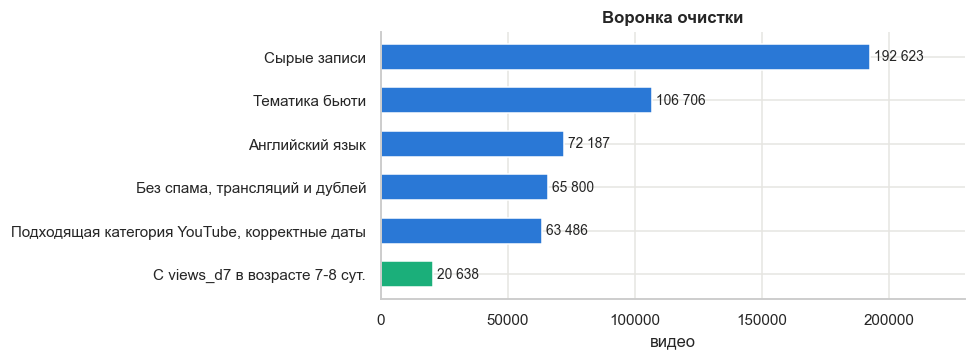

,этап,видео,каналов,% от сырых
0,Сырые записи,192623,12184,100.0
1,Тематика бьюти,106706,11841,55.4
2,Английский язык,72187,8578,37.5
3,"Без спама, трансляций и дублей",65800,8531,34.2
4,"Подходящая категория YouTube, корректные даты",63486,8218,33.0
5,С views_d7 в возрасте 7-8 сут.,20638,4831,10.7


In [14]:
steps = [("Сырые записи", np.ones(len(df), bool)),
         ("Тематика бьюти", df.is_beauty),
         ("Английский язык", df.is_en),
         ("Без спама, трансляций и дублей", ~(df.is_spam | df.is_live | df.is_dup_title)),
         ("Подходящая категория YouTube, корректные даты", ~(df.offtopic_yt_cat | df.bad_dates))]
m = np.ones(len(df), bool)
fun = []
for name, s in steps:
    m &= np.asarray(s)
    fun.append((name, int(m.sum()), df.loc[m, "channel_id"].nunique()))
df["clean"] = m
fun.append(("С views_d7 в возрасте 7-8 сут.", int((df.clean & df.has_d7).sum()),
            df.loc[df.clean & df.has_d7, "channel_id"].nunique()))
funnel = pd.DataFrame(fun, columns=["этап", "видео", "каналов"])
funnel["% от сырых"] = (funnel["видео"] / len(df) * 100).round(1)

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(funnel["этап"][::-1], funnel["видео"][::-1], color=([C[0]] * 5 + [C[2]])[::-1], height=0.6)
for i, v in enumerate(funnel["видео"][::-1]):
    ax.text(v + 1500, i, fmt(v), va="center", fontsize=9)
ax.set_title("Воронка очистки")
ax.set_xlabel("видео")
ax.set_xlim(0, 230000)
plt.tight_layout()
plt.show()
funnel

In [15]:
df[df.is_en & ~df.is_beauty].sample(10, random_state=SEED)[["found_by_tag", "channel_title", "title"]]

,found_by_tag,channel_title,title
30960,#lashes,Catafreer,💫🤍✨ 🧚
78744,#nails,XuanBac_1n1,The worst is when you literally catch them in a lie #shqiptaretneperb...
25457,#manicure,Niki Fulmer,Summer must have for little kids ☀️💦 #waterslide #tiktokshopcreatorpicks #tiktokshopst...
88488,#scentoftheday,Bobby’s world of reviews,No Drill Camera Mount FINALLY Works on Vinyl Siding
38629,#browlamination,Savannah Mares,Rebuilding my dream life & ur coming with⭐️ #actresslife #diml #startingover #contentc...
156462,#lashextensions,Juria Meow,"With 4.9 stars on Google, I had to see if The Burger Monk lived up to the hype—"
56004,#nails,SachaFierce,This Halloween Costume is EVERYTHING! 🎃 Name the Movie!
69577,#lashes,LyndsieLately,"molilito Artificial Peony Flowers, 20 Stems for We..."
162461,#nails,Marina Jones,She was on a mission
52662,#browlamination,Priscilla Pope,DAY 2 DCC PREP INTENSIVE VLOG 👀💙 #dcc #dallascowboyscheerleaders #dccprepclass #dccpre...


In [16]:
short = df[df.is_short & df.has_d7]
print(f"Shorts с d7: {fmt(len(short))}, не проходят тематику или язык: {(~(short.is_beauty & short.is_en)).mean():.0%}")
print(f"не про бьюти: {(~short.is_beauty).mean():.0%} | не на английском: {(~short.is_en).mean():.0%}")

Shorts с d7: 51 947, не проходят тематику или язык: 59%
не про бьюти: 42% | не на английском: 33%


Больше всего записей отсекает тематический фильтр (45%), на втором месте язык (32% оставшихся). Чистыми остаются
63 486 видео, с целевой переменной 20 638.

Фильтра по длительности и списка новостных каналов недостаточно: среди Shorts с `views_d7` 59% не проходят тематику
или язык. Основной мусор составляют короткие ролики про еду, товары и быт, по длительности их не отличить.
Среди отсеянных англоязычных видео выше видны обзоры техники, кулинария и влоги.

### Ручная проверка фильтров

Размечено 100 случайных принятых и 100 случайных отсеянных записей. Поле `relevant` отмечает англоязычное видео
про бьюти или уход за собой.

In [17]:
man = pd.read_csv(MANUAL)
assert set(man.video_id) <= set(df.video_id)
man["в выборке"] = man.video_id.map(df.set_index("video_id").clean)
assert (man["в выборке"] == man.group.eq("kept")).all()


def wilson(k, n, z=1.96):
    p = k / n
    d = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / d
    w = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return c - w, c + w


prec_k, prec_n = man.query("group == 'kept'").relevant.sum(), (man.group == "kept").sum()
miss_k, miss_n = man.query("group == 'rejected'").relevant.sum(), (man.group == "rejected").sum()
rel_kept = prec_k / prec_n * int(df.clean.sum())
rel_rej = miss_k / miss_n * int((~df.clean).sum())
lo, hi = wilson(prec_k, prec_n)
print(f"точность: {prec_k / prec_n:.0%}, 95% ДИ {lo:.0%}...{hi:.0%}")
lo, hi = wilson(miss_k, miss_n)
print(f"доля релевантных среди отсеянных: {miss_k / miss_n:.0%}, 95% ДИ {lo:.0%}...{hi:.0%}")
print(f"полнота: {rel_kept / (rel_kept + rel_rej):.0%}")
man[man.note.notna()][["group", "note", "title"]]

точность: 85%, 95% ДИ 77%...91%
доля релевантных среди отсеянных: 8%, 95% ДИ 4%...15%
полнота: 84%


,group,note,title
0,kept,эфирные масла/ароматерапия,What are some common uses for aniseed? 🌿 #Shorts
8,kept,здоровье (суставы),"I Couldn’t Walk, BUT NOW I CAN RUN AGAIN! A 100 Year Old Aloe Remedy for Aching Joints!"
13,kept,техника,LibreWolf vs Mullvad Browser vs Brave: Which Privacy Browser Is Worth It? (2026)
17,kept,ёлка,"Transform Your Christmas Tree: Discover the Secret to a Greener, Longer-Lasting Tree!"
19,kept,зоотовары,BUY 1 GET 1 FREE - Native Pet Hairball Treatment f...
20,kept,тагальский язык,San ko daw nabili yung eros ko? #Shorts #juliusbagauisan
26,kept,религиозный ритуал,🌺 A Peaceful Morning Ritual of Offering Flowers
41,kept,фитнес,"GIRLLLL, if you want to see some REAL GAINS by summer 2027, you need to start NOW! 😭🍑💪..."
43,kept,бижутерия,Stunning 14K Gold Plated Bracelets: The Perfect Accessory for Every Occasion!
45,kept,сумка,Makeup 💄 Nails 💅🏻 Personal Care 🧖🏻‍♀️ Hair - this travel toiletry bag fits at all!! BA...


Точность фильтра 85% (95% ДИ 77-91%). Ошибки дают пограничные товарные ролики (аромамасла, бижутерия, сумка)
и единичные неанглийские тексты на латинице. Полнота около 84%: больше половины потерь составляют англоязычные ролики
с ошибочным `default_language`. Для EDA и первых моделей качества хватает, к чекпойнту 3 языковое правило стоит смягчить.

### Качество хэштегов поиска

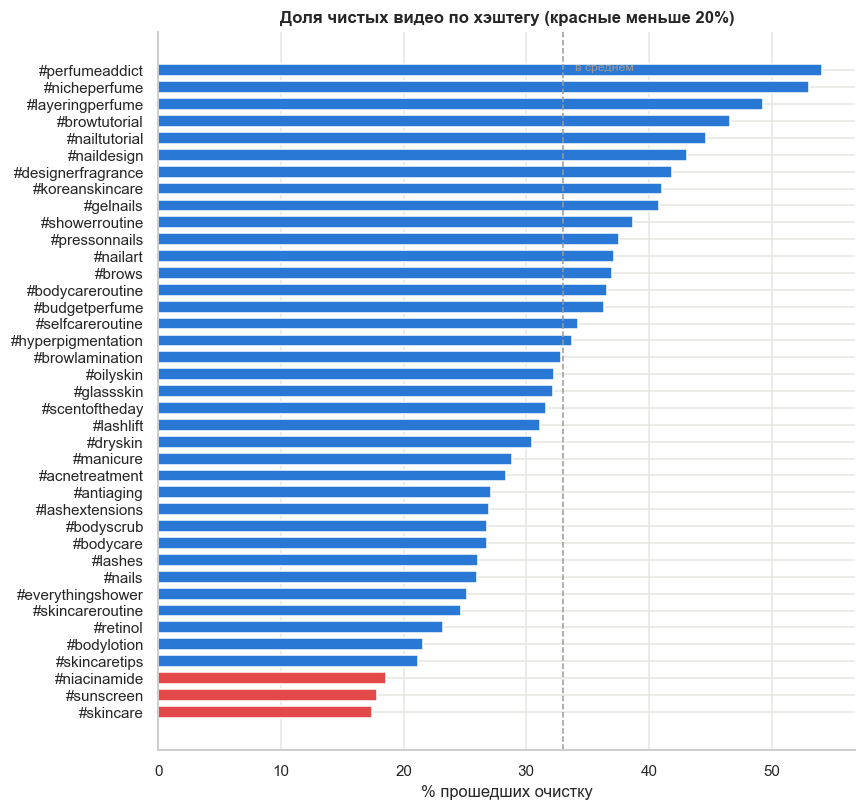

,видео,доля_чистых,доля_en,доля_beauty
found_by_tag,,,,
#skincare,3345,0.17,0.32,0.48
#sunscreen,3710,0.18,0.39,0.42
#niacinamide,4069,0.19,0.60,0.49
#skincaretips,3121,0.21,0.33,0.54
#bodylotion,3808,0.22,0.53,0.43
#retinol,3540,0.23,0.49,0.52


In [18]:
tag_q = df.groupby("found_by_tag").agg(видео=("video_id", "size"), доля_чистых=("clean", "mean"),
                                        доля_en=("is_en", "mean"), доля_beauty=("is_beauty", "mean")).sort_values("доля_чистых")
fig, ax = plt.subplots(figsize=(8, 7.5))
ax.barh(tag_q.index, tag_q.доля_чистых * 100, color=[C[7] if v < .2 else C[0] for v in tag_q.доля_чистых], height=0.7)
ax.axvline(df.clean.mean() * 100, color=GREY, ls="--", lw=1)
ax.text(df.clean.mean() * 100 + 1, len(tag_q) - 1, "в среднем", color=GREY, fontsize=8)
ax.set_title("Доля чистых видео по хэштегу (красные меньше 20%)")
ax.set_xlabel("% прошедших очистку")
plt.tight_layout()
plt.show()
tag_q.head(6).round(2)

Хуже всего работают общие теги ухода за кожей (`#skincare`, `#sunscreen`, `#niacinamide`): меньше половины их выдачи
на английском и половина не про бьюти. Хэштеги с долей чистых меньше 20% стоит заменить на более узкие.

## 5. Итоговая выборка

Дальше работаем с чистыми видео, у которых `views_d7` снят в возрасте 7-8 суток. Подписчики и страну канала берём
из таблицы `channels.parquet`.

In [19]:
q = df[df.clean & df.has_d7].copy().reset_index(drop=True)
q["y"] = np.log1p(q.views_d7)
ch = channels.set_index("channel_id")
q["subscribers"] = q.channel_id.map(ch.subscribers)
q["country"] = q.channel_id.map(ch.country).fillna("не указана")
q["format"] = np.where(q.is_short, "Shorts (до 3 мин)", "обычное видео")
per_ch = q.channel_id.value_counts()
pd.Series({
    "видео": fmt(len(q)),
    "каналов": fmt(q.channel_id.nunique()),
    "период публикации": f"{q.published_at.min():%d.%m} ... {q.published_at.max():%d.%m.%Y}",
    "Shorts / обычные": f"{q.is_short.mean():.0%} / {1 - q.is_short.mean():.0%}",
    "видео на канал: медиана / макс.": f"{per_ch.median():.0f} / {per_ch.max()}",
    "доля топ-10 каналов": f"{per_ch.head(10).sum() / len(q):.1%}",
    "доля с полным горизонтом среди чистых": f"{len(q) / df.clean.sum():.1%}",
    "чистые старше 8 сут. без d7": f"{(~df.loc[df.clean & (df.age_now_d >= 8), 'has_d7']).mean():.1%}",
}).to_frame("значение")

,значение
видео,20 638
каналов,4 831
период публикации,25.10 ... 01.11.2026
Shorts / обычные,93% / 7%
видео на канал: медиана / макс.,2 / 151
доля топ-10 каналов,4.2%
доля с полным горизонтом среди чистых,32.5%
чистые старше 8 сут. без d7,7.1%


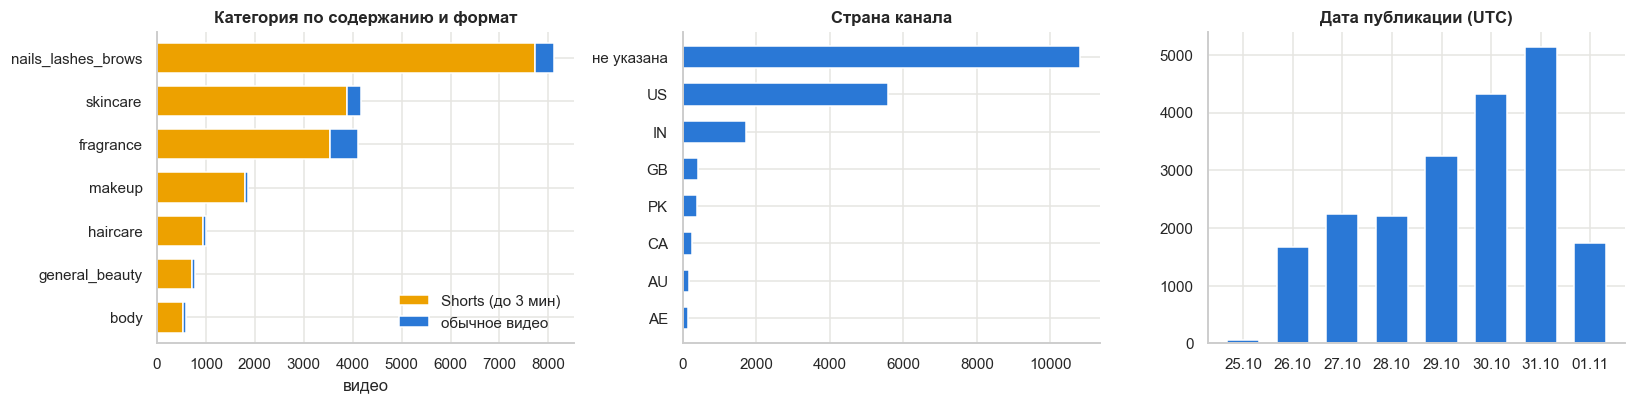

доля стран, %: {'не указана': 52.3, 'US': 27.0, 'IN': 8.4, 'GB': 2.0, 'PK': 1.9, 'CA': 1.3}


content_category,body,fragrance,general_beauty,haircare,makeup,nails_lashes_brows,skincare,итого
beauty_category,,,,,,,,
body,239,20,95,117,86,49,305,911
fragrance,67,3886,123,74,142,126,541,4959
nails_lashes_brows,198,154,456,689,1465,7903,1957,12822
skincare,94,45,111,125,160,47,1364,1946
итого,598,4105,785,1005,1853,8125,4167,20638


In [20]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
cc = pd.crosstab(q.content_category, q.format)
cc.loc[cc.sum(1).sort_values().index].plot.barh(stacked=True, ax=ax[0], color=[C[3], C[0]], width=.7)
ax[0].set_title("Категория по содержанию и формат")
ax[0].set_xlabel("видео")
ax[0].set_ylabel("")
ax[0].legend(frameon=False)
top_c = q.country.value_counts().head(8)
ax[1].barh(top_c.index[::-1], top_c.values[::-1], color=C[0], height=.6)
ax[1].set_title("Страна канала")
pdate = q.published_at.dt.normalize().value_counts().sort_index()
ax[2].bar(pdate.index.strftime("%d.%m"), pdate.values, color=C[0], width=.65)
ax[2].set_title("Дата публикации (UTC)")
plt.tight_layout()
plt.show()
print("доля стран, %:", (q.country.value_counts(normalize=True).head(6) * 100).round(1).to_dict())
pd.crosstab(q.beauty_category, q.content_category, margins=True, margins_name="итого")

* **Объём:** 20 638 видео от 4 831 канала, публикации с 25 октября по 1 ноября. Остальные чистые видео ещё не прожили
  семи суток и войдут в выборку по мере сбора.
* **Формат:** 93% Shorts, обычных видео около 1.5 тысячи, формат идёт признаком.
* **Категории.** Категория хэштега расходится с содержанием: из 12.8 тысячи видео, найденных через ногтевые хэштеги,
  про ногти, ресницы и брови только 7.9 тысячи. Дальше используем категорию по содержанию `content_category`.
  Перекос к ногтям (39%) возник потому, что выгрузку собирал один участник.
* **Каналы:** медиана 2 видео на канал, максимум 151, на топ-10 каналов приходится 4.2% выборки.
* **География:** у половины каналов страна не указана, среди указанных лидируют США и Индия.
* **Время:** две недели одного сезона, сезонность по этим данным не оценить.

## 6. Целевая переменная

count       20638.0
mean        11001.0
std        163377.0
min             0.0
10%            10.0
25%            75.0
50%           934.0
75%          1612.0
90%          9448.0
99%        141898.0
max      16817382.0

0 просмотров: 1.4% | меньше 100: 27.6% | от 100k: 1.3%
топ-1% видео собирает 66% просмотров, топ-10% собирает 91%


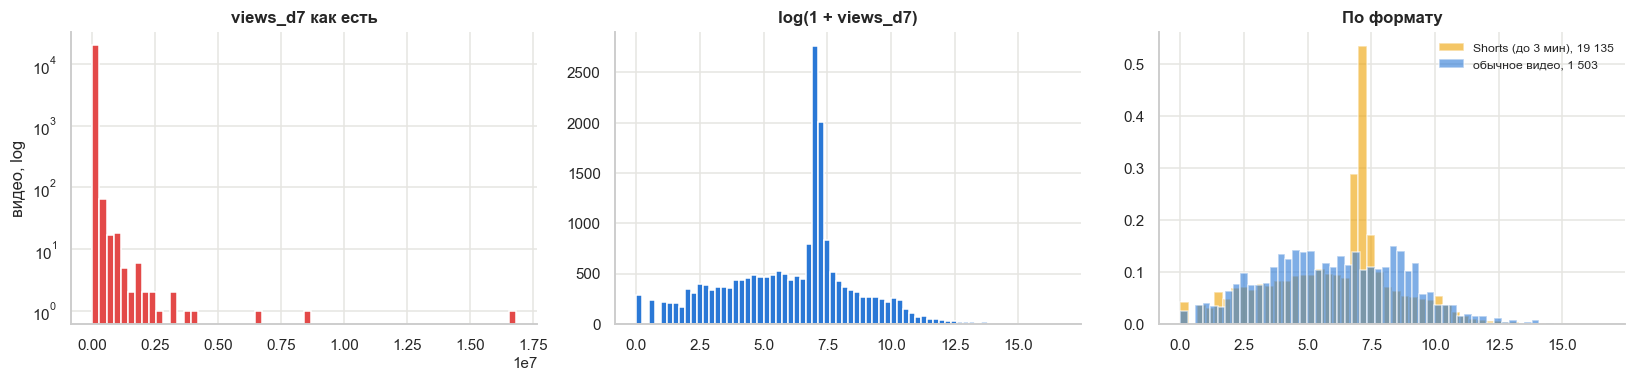

In [21]:
v = q.views_d7
print(v.describe(percentiles=[.1, .25, .5, .75, .9, .99]).round(0).to_string())
print(f"\n0 просмотров: {(v == 0).mean():.1%} | меньше 100: {(v < 100).mean():.1%} | от 100k: {(v >= 1e5).mean():.1%}")
print(f"топ-1% видео собирает {v.nlargest(len(v) // 100).sum() / v.sum():.0%} просмотров, "
      f"топ-10% собирает {v.nlargest(len(v) // 10).sum() / v.sum():.0%}")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(v, bins=60, color=C[7])
ax[0].set_yscale("log")
ax[0].set_title("views_d7 как есть")
ax[0].set_ylabel("видео, log")
ax[1].hist(q.y, bins=70, color=C[0])
ax[1].set_title("log(1 + views_d7)")
for i, (lab, s) in enumerate(q.groupby("format").y):
    ax[2].hist(s, bins=50, density=True, alpha=.6, color=[C[3], C[0]][i], label=f"{lab}, {fmt(len(s))}")
ax[2].legend(frameon=False, fontsize=8)
ax[2].set_title("По формату")
plt.tight_layout()
plt.show()

Медиана 934 просмотра при среднем 11 001 и максимуме 16.8 миллиона. Верхний 1% роликов собирает 66% всех просмотров.
Среднее не описывает типичное видео, поэтому моделируем логарифм `y = log(1 + views_d7)`. После логарифмирования
в распределении виден резкий пик около тысячи просмотров.

In [22]:
mode = q[(q.views_d7 >= 990) & (q.views_d7 < 2000)]
print(f"видео с 990-1 999 просмотрами: {fmt(len(mode))} ({len(mode) / len(q):.0%}), каналов: {fmt(mode.channel_id.nunique())}, "
      f"максимум у одного канала: {mode.channel_id.value_counts().max()}")
print(f"доля Shorts в пике: {mode.is_short.mean():.0%} (во всей выборке {q.is_short.mean():.0%})")
regime = pd.cut(q.views_d7, [-1, 100, 989, 1999, 1e5, 1e9], labels=["до 100", "101-989", "990-1 999", "2 000-100k", "больше 100k"])
traj = {f"медиана views_d{k}": q.groupby(regime, observed=True)[f"views_d{k}"].median() for k in (1, 3, 5)}
pd.concat([q.groupby(regime, observed=True).agg(видео=("y", "size"), доля_shorts=("is_short", "mean"),
                                                 медиана_подписчиков=("subscribers", "median")),
           pd.DataFrame(traj), q.groupby(regime, observed=True).views_d7.median().rename("медиана views_d7")], axis=1).round(2)

видео с 990-1 999 просмотрами: 5 561 (27%), каналов: 2 365, максимум у одного канала: 37
доля Shorts в пике: 98% (во всей выборке 93%)


,видео,доля_shorts,медиана_подписчиков,медиана views_d1,медиана views_d3,медиана views_d5,медиана views_d7
views_d7,,,,,,,
до 100,5727,0.91,65.0,3.0,11.0,15.0,18.0
101-989,4912,0.91,412.0,385.5,343.0,345.5,332.0
990-1 999,5561,0.98,414.0,1205.0,1236.5,1248.0,1252.0
2 000-100k,4168,0.89,19000.0,5048.0,6506.0,6652.5,7283.5
больше 100k,270,0.89,93250.0,114026.5,198301.0,228387.0,257587.5


В распределении три режима.
1. **Ролики почти без показов**, до 100 просмотров (28% выборки). Медиана подписчиков у таких каналов 65.
2. **Пик 1-2 тысячи просмотров** (27% выборки, 98% из них Shorts). Пик распределён по 2.4 тысячи каналов, на один
   канал приходится не больше 37 видео, поэтому накрутку или одного автора исключаем. Такие видео набирают около
   1 200 просмотров в первые сутки и к седьмому дню добавляют лишь 4%. Похоже на тестовый показ ленты: ролик показывают
   стартовой аудитории и при слабом отклике дальше не продвигают.
3. **Хвост**, больше 2 тысяч просмотров (21%). Каналы здесь на порядки крупнее: медиана 19 тысяч подписчиков.

Регрессию полезно дополнить классификацией «вышел ли ролик за тестовый показ», а ошибку считать отдельно по режимам.

## 7. Выбросы

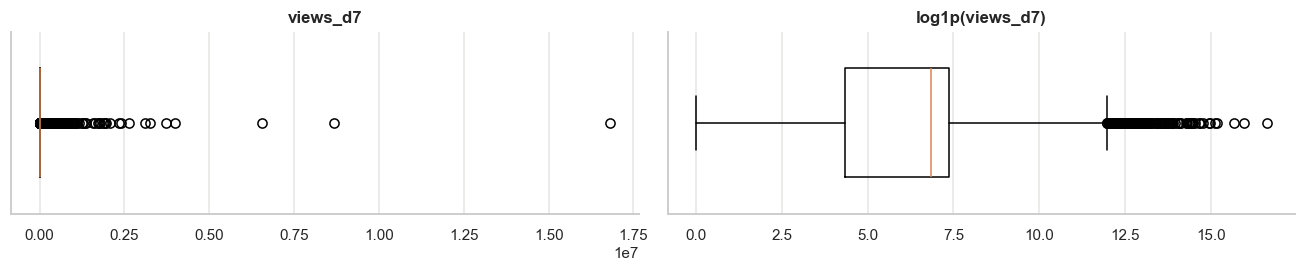

,выбросов по IQR,"доля, %",граница сверху,максимум
признак,,,,
views_d7,3171,15.4,3916.90,16817382.00
likes_d7,3173,15.8,61.00,169627.00
comments_d7,3363,16.4,2.50,19466.00
duration_s,2307,11.2,121.50,10792.00
log1p(views_d7),187,0.9,11.97,16.64


In [23]:
rows = []
for c in ["views_d7", "likes_d7", "comments_d7", "duration_s"]:
    s = q[c].dropna()
    q1, q3 = s.quantile([.25, .75])
    hi = q3 + 1.5 * (q3 - q1)
    rows.append({"признак": c, "выбросов по IQR": int((s > hi).sum()), "доля, %": round(100 * (s > hi).mean(), 1),
                 "граница сверху": round(hi, 1), "максимум": s.max()})
s = q.y
q1, q3 = s.quantile([.25, .75])
lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
rows.append({"признак": "log1p(views_d7)", "выбросов по IQR": int(((s < lo) | (s > hi)).sum()),
             "доля, %": round(100 * ((s < lo) | (s > hi)).mean(), 1), "граница сверху": round(hi, 2),
             "максимум": round(s.max(), 2)})
fig, ax = plt.subplots(1, 2, figsize=(12, 2.6))
ax[0].boxplot(q.views_d7, vert=False, widths=.6)
ax[0].set_title("views_d7")
ax[0].set_yticks([])
ax[1].boxplot(q.y, vert=False, widths=.6)
ax[1].set_title("log1p(views_d7)")
ax[1].set_yticks([])
plt.tight_layout()
plt.show()
pd.DataFrame(rows).set_index("признак")

По правилу полутора межквартильных размахов выбросами оказываются 15% значений `views_d7` (всё выше 3 900 просмотров)
и любое видео с тремя комментариями. Правило рассчитано на симметричные распределения и для логнормального не подходит.
Вирусные ролики остаются в выборке: они реальны и интересуют заказчика больше всего. Вместо удаления логарифмируем цель,
на логарифмической шкале за границы выходит лишь 0.9% значений. Ошибочные значения уже убраны при очистке.

## 8. Признаки и их связь с целевой переменной

Берём признаки, известные до публикации: длительность, формат, заголовок, описание, теги, реклама, язык аудио
и время публикации. Число подписчиков отмечено звёздочкой: в выгрузке его сняли через несколько дней после публикации.

In [24]:
t = q.title.fillna("")
d = q.description.fillna("")
F = pd.DataFrame(index=q.index)
F["duration_log"] = np.log1p(q.duration_s)
F["title_len"] = t.str.len()
F["title_words"] = t.str.split().str.len()
F["n_hashtags_title"] = t.str.count(r"#\w+")
F["n_emoji_title"] = t.map(lambda s: sum(unicodedata.category(c) == "So" for c in s))
F["caps_words"] = t.map(lambda s: sum(len(w) > 2 and w.isupper() for w in s.split()))
F["has_question"] = t.str.contains("?", regex=False).astype(int)
F["has_number"] = t.str.contains(r"\d").astype(int)
F["has_description"] = d.str.len().gt(0).astype(int)
F["desc_len"] = d.str.len()
F["desc_links"] = d.str.count(r"https?://")
F["n_tags"] = q.tags.fillna("[]").map(lambda s: len(json.loads(s)) if s.startswith("[") else 0)
F["is_ad"] = q.is_ad.astype(int)
F["has_audio_lang"] = q.default_audio_language.notna().astype(int)
F["hour_utc"] = q.published_at.dt.hour
F["weekday"] = q.published_at.dt.weekday
F["is_short"] = q.is_short.astype(int)
F["log_subscribers*"] = np.log1p(q.subscribers)
F.describe().T[["mean", "50%", "max"]].round(2)

,mean,50%,max
duration_log,3.51,3.30,9.29
title_len,68.85,71.00,100.00
title_words,10.19,10.00,24.00
n_hashtags_title,2.03,1.00,16.00
n_emoji_title,0.75,0.00,14.00
caps_words,0.52,0.00,17.00
has_question,0.10,0.00,1.00
has_number,0.19,0.00,1.00
has_description,0.68,1.00,1.00
desc_len,345.82,222.00,1108.00


Медианный заголовок содержит 71 символ и 10 слов, максимум упирается в лимит YouTube в 100 символов. Описание есть
у 68% роликов, реклама у 9%, медианная длительность 26 секунд.

### Попарные распределения

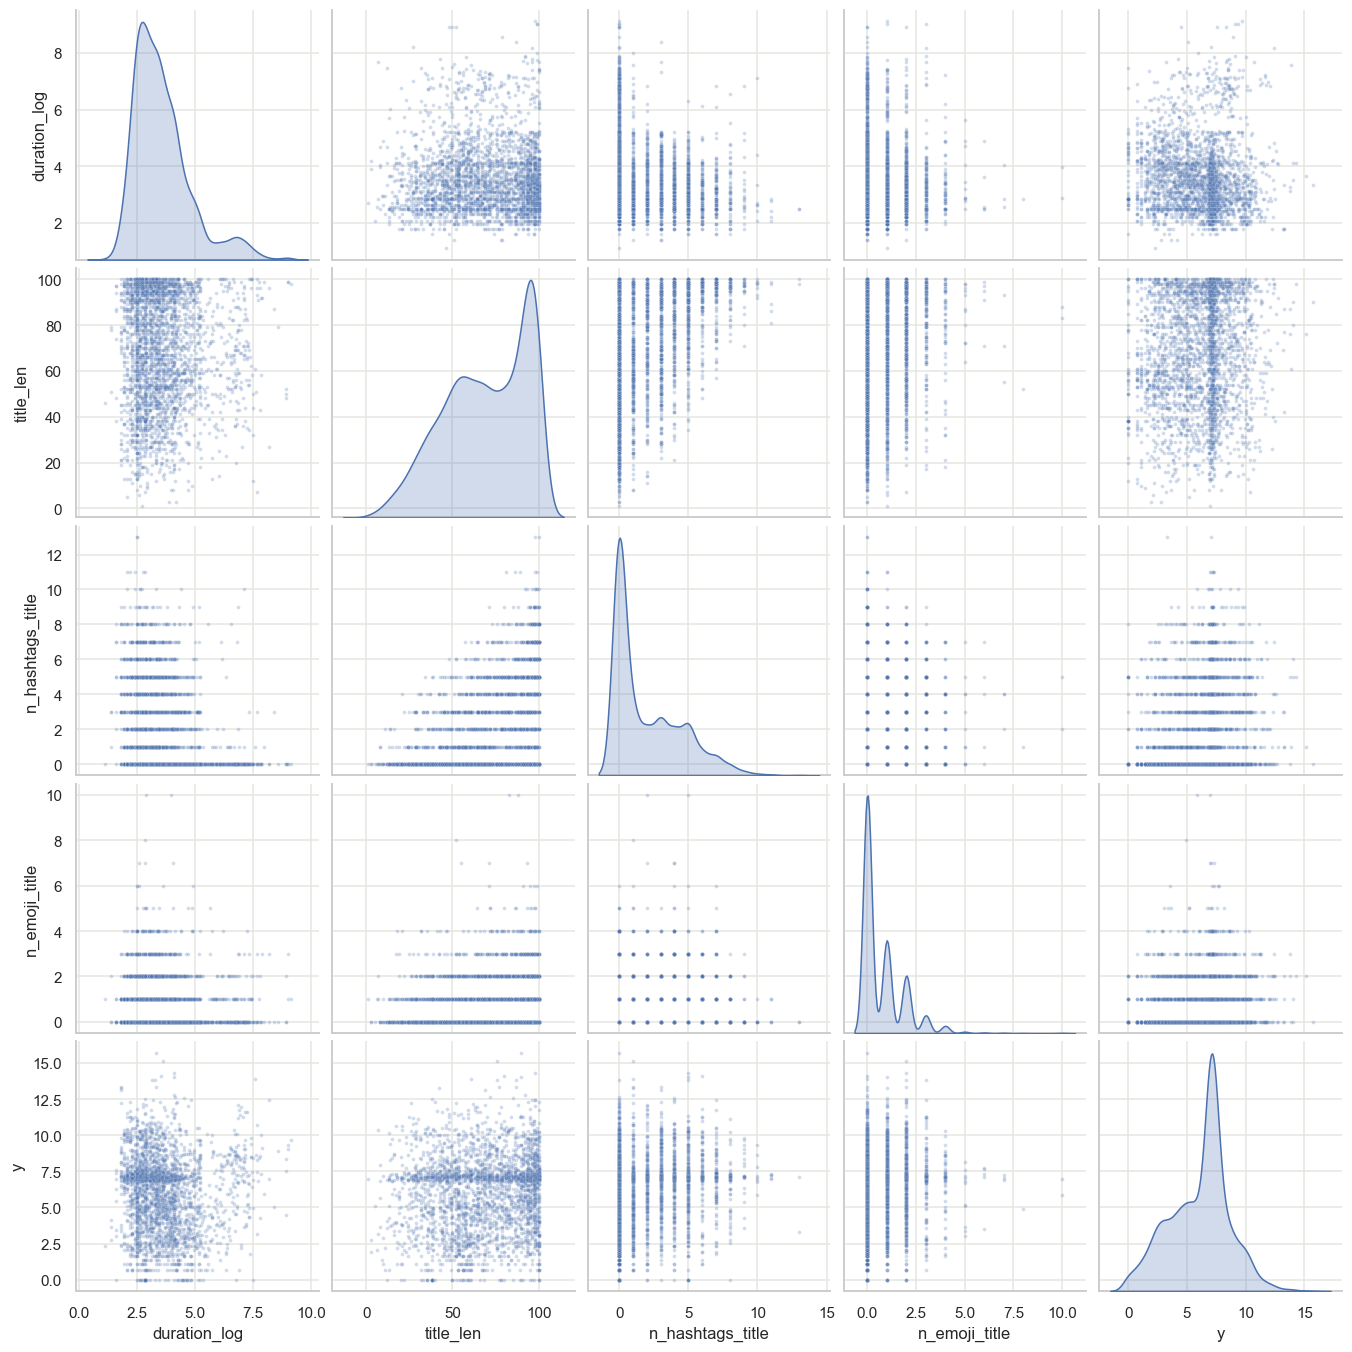

In [25]:
pair = F[["duration_log", "title_len", "n_hashtags_title", "n_emoji_title"]].assign(y=q.y)
sns.pairplot(pair.sample(3000, random_state=SEED), diag_kind="kde", plot_kws={"s": 6, "alpha": .25})
plt.show()

Хэштеги и эмодзи дискретны с пиком в нуле, длина заголовка скапливается у лимита в 100 символов, логарифм длительности
скошен. На диаграммах рассеяния явных зависимостей с целевой переменной нет, связи слабые.

### Корреляции с целевой переменной

Считаем корреляцию Спирмена двумя способами: по всей выборке и внутри канала, после вычитания среднего по каналу
из признака и из цели. Второй способ показывает, меняются ли просмотры, если тот же автор делает ролик иначе.

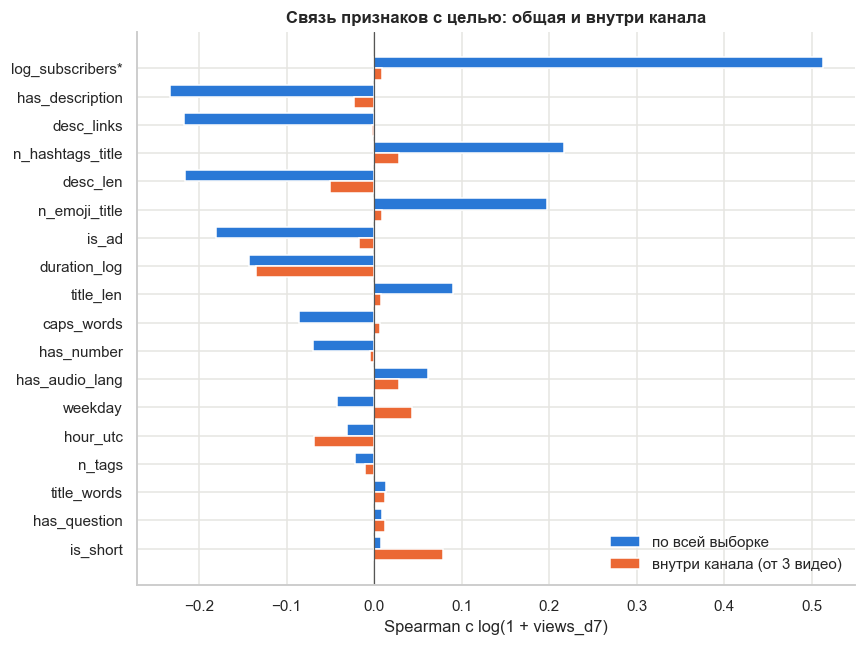

,по всей выборке,внутри канала
log_subscribers*,0.513,0.009
has_description,-0.233,-0.023
desc_links,-0.217,-0.002
n_hashtags_title,0.217,0.028
desc_len,-0.216,-0.051
n_emoji_title,0.198,0.010
is_ad,-0.181,-0.017
duration_log,-0.143,-0.135
title_len,0.090,0.008
caps_words,-0.085,0.007


In [26]:
multi = q.channel_id.map(q.channel_id.value_counts()) >= 3


def within(col):
    s, y, g = F.loc[multi, col], q.loc[multi, "y"], q.loc[multi, "channel_id"]
    dx, dy = s - s.groupby(g).transform("mean"), y - y.groupby(g).transform("mean")
    return dx.corr(dy, method="spearman") if dx.std() > 0 else np.nan


cor = pd.DataFrame({"по всей выборке": [rho(F[c], q.y) for c in F.columns],
                    "внутри канала": [within(c) for c in F.columns]}, index=F.columns)
cor = cor.reindex(cor["по всей выборке"].abs().sort_values().index)
fig, ax = plt.subplots(figsize=(8, 6))
yy = np.arange(len(cor))
ax.barh(yy + .2, cor["по всей выборке"], height=.4, color=C[0], label="по всей выборке")
ax.barh(yy - .2, cor["внутри канала"], height=.4, color=C[1], label="внутри канала (от 3 видео)")
ax.set_yticks(yy)
ax.set_yticklabels(cor.index)
ax.axvline(0, color="#555", lw=.8)
ax.set_xlabel("Spearman с log(1 + views_d7)")
ax.set_title("Связь признаков с целью: общая и внутри канала")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()
cor.iloc[::-1].round(3)

По всей выборке описание, ссылки и реклама связаны с просмотрами отрицательно (около -0.2), хэштеги и эмодзи
положительно (около +0.2). Сильнее всего связаны подписчики (0.51).

Внутри канала почти все эти связи исчезают (не больше 0.05 по модулю). Описание, эмодзи и хэштеги характеризуют тип
автора, магазин или салон против органического блогера, а не сам ролик. Устойчивой внутри канала остаётся длительность
(-0.14): у того же автора короткий ролик набирает больше. Слабее работают формат Shorts (+0.08) и час публикации (-0.07).

### Срезы по группам

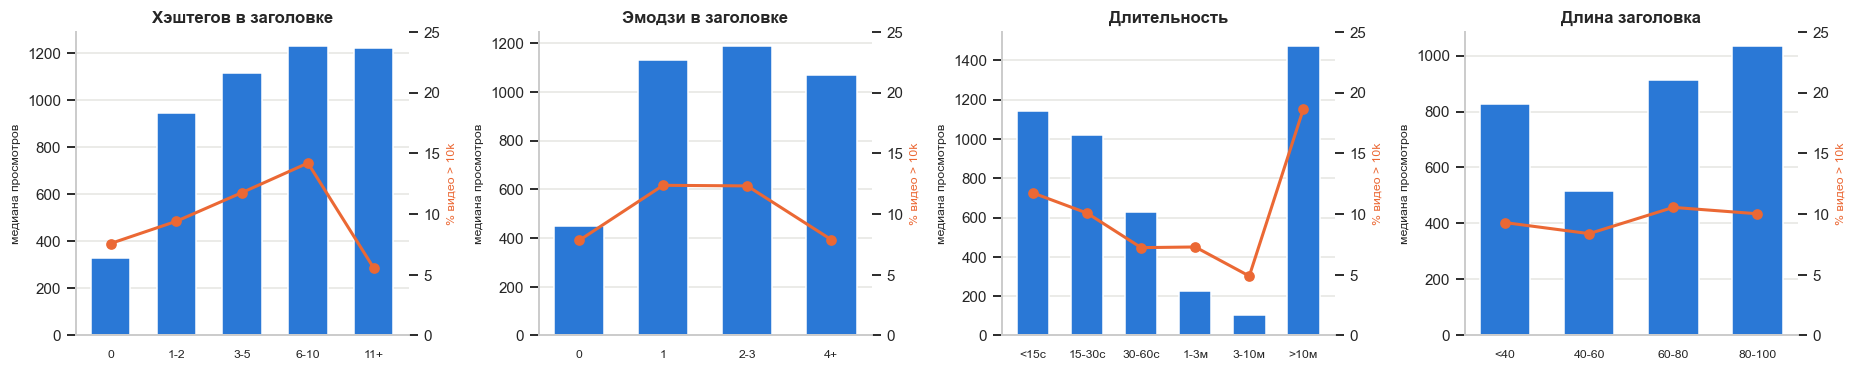

видео  медиана  доля_выше_10k
признак          группа                               
n_hashtags_title 0        9273    329.0          0.076
                 1-2      3765    945.0          0.094
                 3-5      5591   1118.0          0.118
                 6-10     1937   1230.0          0.142
                 11+        72   1223.0          0.056
n_emoji_title    0       11752    451.0          0.078
                 1        4481   1129.0          0.124
                 2-3      3898   1187.0          0.123
                 4+        507   1071.0          0.079
duration_log     <15с     6070   1140.5          0.117
                 15-30с   5470   1021.0          0.101
                 30-60с   4425    629.0          0.072
                 1-3м     3170    226.0          0.073
                 3-10м     736    104.5          0.049
                 >10м      767   1471.0          0.186
title_len        <40      3078    827.0          0.093
                 40-60    4711    517.0          0.084
                 60-80    4656    914.0          0.105
                 80-100   8193   1033.0          0.100

In [27]:
def srez(col, bins, labels):
    b = pd.cut(F[col], bins, labels=labels)
    return q.groupby(b, observed=True).agg(видео=("y", "size"), медиана=("views_d7", "median"),
                                           доля_выше_10k=("views_d7", lambda s: (s > 1e4).mean()))


cuts = {"n_hashtags_title": ([-1, 0, 2, 5, 10, 100], ["0", "1-2", "3-5", "6-10", "11+"]),
        "n_emoji_title": ([-1, 0, 1, 3, 100], ["0", "1", "2-3", "4+"]),
        "duration_log": (np.log1p([-.5, 15, 30, 60, 180, 600, 1e7]), ["<15с", "15-30с", "30-60с", "1-3м", "3-10м", ">10м"]),
        "title_len": ([0, 40, 60, 80, 100], ["<40", "40-60", "60-80", "80-100"])}
names = {"n_hashtags_title": "Хэштегов в заголовке", "n_emoji_title": "Эмодзи в заголовке",
         "duration_log": "Длительность", "title_len": "Длина заголовка"}
fig, ax = plt.subplots(1, 4, figsize=(17, 3.5))
tabs = {}
for a, (col, (b, lab)) in zip(ax, cuts.items()):
    s = srez(col, b, lab)
    tabs[col] = s
    a.bar(s.index.astype(str), s.медиана, color=C[0], width=.6)
    a2 = a.twinx()
    a2.plot(s.index.astype(str), s.доля_выше_10k * 100, color=C[1], marker="o", lw=2)
    a2.set_ylim(0, 25)
    a2.grid(False)
    a2.set_ylabel("% видео > 10k", color=C[1], fontsize=8)
    a.set_title(names[col])
    a.set_ylabel("медиана просмотров", fontsize=8)
    a.tick_params(axis="x", labelsize=8)
    a.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
pd.concat(tabs, names=["признак", "группа"]).round(3)

Столбцы показывают медиану просмотров, линия долю видео больше 10 тысяч.
* **Хэштеги:** без них медиана 329, при 3-10 хэштегах 1 100-1 230, при 11 и больше доля вирусных падает с 14% до 6%.
* **Эмодзи:** оптимум 1-3 (медиана около 1 150 против 451 без эмодзи), при четырёх и больше доля вирусных снова падает.
* **Длительность:** лучше всего ролики короче 15 секунд (1 140), хуже всего от минуты до десяти (100-230), видео
  длиннее 10 минут снова высокие (1 470), их снимают более крупные каналы.
* **Длина заголовка** почти не влияет.

Зависимости нелинейные, линейная модель их не уловит, нужны деревья или бинирование.

### Описание, реклама и категории

In [28]:
grp = q.assign(описание=F.has_description.map({0: "нет", 1: "есть"}), реклама=q.is_ad.map({False: "нет", True: "да"}))
print("медиана просмотров:")
print(grp.pivot_table(index="описание", columns="реклама", values="views_d7", aggfunc="median").round(0).to_string())
print("\nмедиана подписчиков канала:")
print(grp.groupby("описание").subscribers.median().to_string())
q.groupby("content_category").agg(видео=("y", "size"), медиана=("views_d7", "median"),
                                  доля_выше_10k=("views_d7", lambda s: (s > 1e4).mean()),
                                  медиана_длительности=("duration_s", "median"),
                                  медиана_подписчиков=("subscribers", "median")).sort_values("медиана").round(2)

медиана просмотров:
реклама       да     нет
описание                
есть        74.0   623.0
нет       1276.0  1222.0

медиана подписчиков канала:
описание
есть    425.0
нет     880.0


,видео,медиана,доля_выше_10k,медиана_длительности,медиана_подписчиков
content_category,,,,,
skincare,4167,268.0,0.09,33.0,468.0
body,598,271.0,0.08,39.0,660.0
fragrance,4105,276.0,0.06,43.0,333.0
general_beauty,785,478.0,0.08,35.0,787.0
haircare,1005,1003.0,0.16,28.0,1310.0
makeup,1853,1139.0,0.11,25.0,1230.0
nails_lashes_brows,8125,1149.0,0.11,18.0,525.0


Без рекламы ролики с описанием набирают 623 просмотра по медиане против 1 222 без описания, рекламные ролики
с описанием 74. Каналы с описаниями вдвое меньше по подписчикам. Вместе с нулевой связью внутри канала получается,
что описание и реклама указывают на коммерческий канал и не служат причиной низких просмотров.

Категории делятся на две группы: ногти, макияж и волосы (медиана 1 000-1 150) против ухода за кожей, тела и парфюмерии
(около 270). Ролики о парфюме вдвое длиннее ногтевых (43 секунды против 18), рассказ о запахе требует времени.

### Время публикации

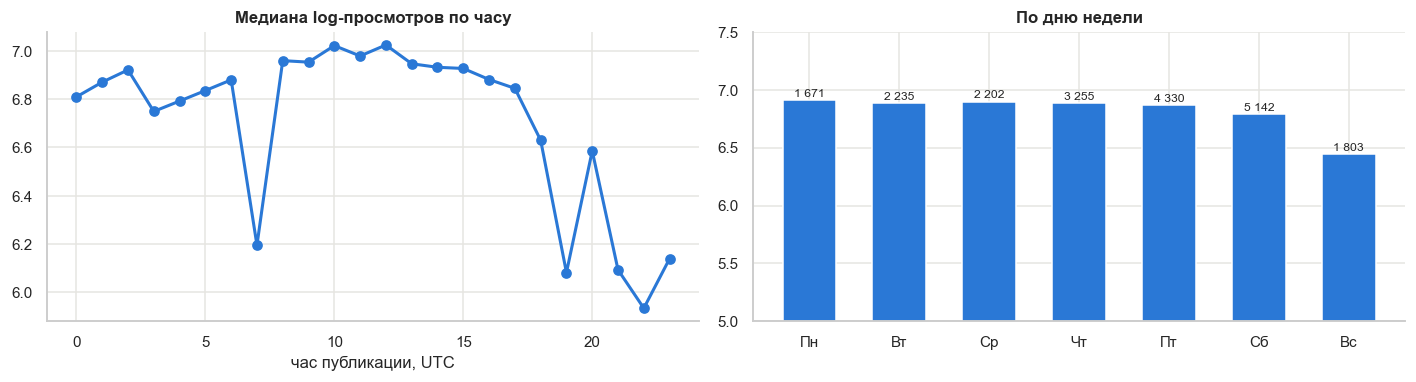

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
hh = q.groupby(F.hour_utc).y.median()
ax[0].plot(hh.index, hh.values, marker="o", color=C[0], lw=2)
ax[0].set_xlabel("час публикации, UTC")
ax[0].set_title("Медиана log-просмотров по часу")
wd = q.groupby(F.weekday).y.agg(["median", "size"])
ax[1].bar(["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"], wd["median"], color=C[0], width=.6)
ax[1].set_ylim(5, 7.5)
ax[1].set_title("По дню недели")
for i, (med, n) in enumerate(wd.values):
    ax[1].text(i, med + .03, fmt(n), ha="center", fontsize=8)
plt.tight_layout()
plt.show()

Связь со временем слабая. Провал воскресенья объясняется срезом: из воскресенья 1 ноября в выборку попали только
ролики до 09:38 UTC, более поздние ещё не дожили до седьмого дня. Час публикации стоит перепроверить в местном
времени по стране канала.

### Корреляции между признаками

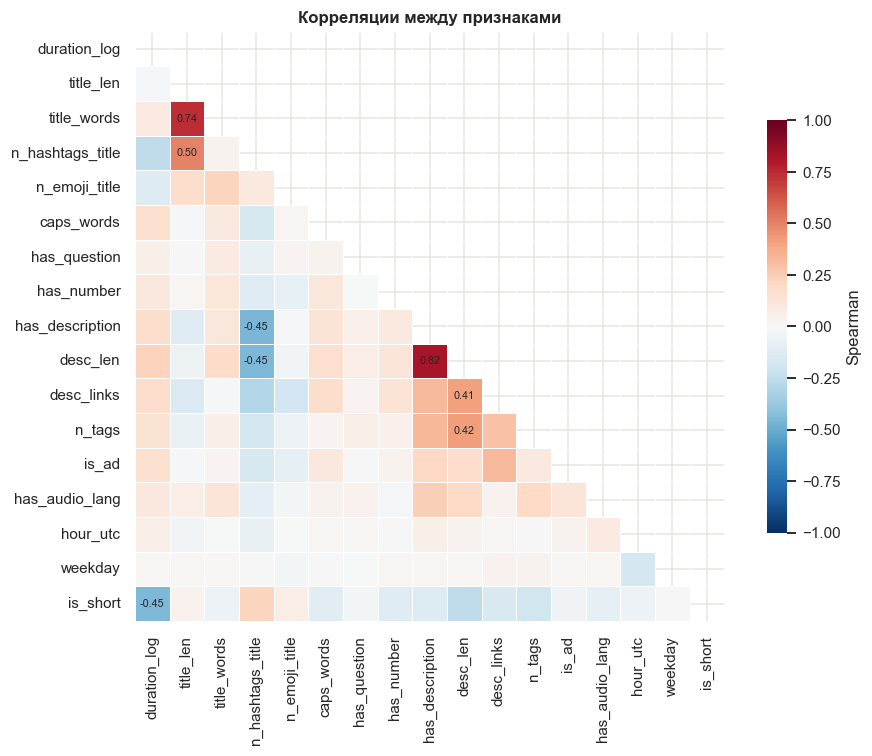

Spearman
has_description  desc_len              0.82
title_len        title_words           0.74
                 n_hashtags_title      0.50
n_hashtags_title has_description      -0.45
duration_log     is_short             -0.45
n_hashtags_title desc_len             -0.45

In [30]:
cm = F.drop(columns=["log_subscribers*"]).corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm, ax=ax, mask=np.triu(np.ones(cm.shape, bool)), cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            linewidths=.4, cbar_kws={"shrink": .7, "label": "Spearman"})
for (i, j), val in np.ndenumerate(cm.values):
    if i > j and abs(val) > .4:
        ax.text(j + .5, i + .5, f"{val:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("Корреляции между признаками")
plt.tight_layout()
plt.show()
cm.where(np.triu(np.ones(cm.shape, bool), 1)).stack().sort_values(key=abs, ascending=False).head(6).round(2).to_frame("Spearman")

Сильно связаны наличие и длина описания (0.82), длина заголовка в символах и словах (0.74), длительность и формат
(-0.45). Хэштеги в заголовке и описание связаны отрицательно (-0.45): авторы либо пишут описание, либо ставят хэштеги.
Деревьям такая связь не мешает, для линейных моделей из пары стоит оставить один признак.

## 9. Каналы

доля разброса log-просмотров, объясняемая каналом: 76%
MAE по среднему других видео канала: 1.00, по общей медиане: 2.04
Spearman подписчиков с целью: 0.51
подписчики сняты после публикации у 100% видео, медианный сдвиг 5.6 сут.


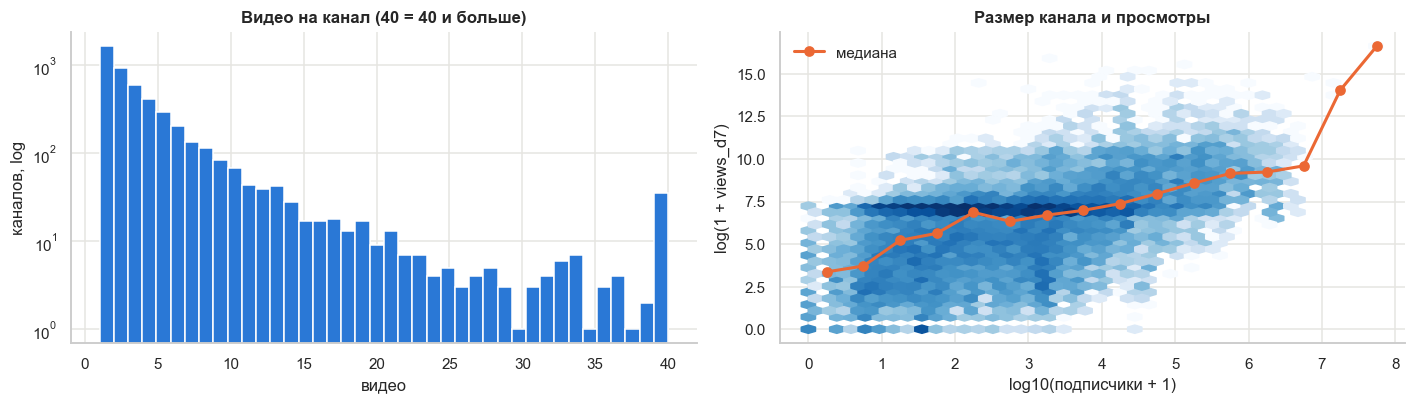

In [31]:
s3 = q[multi]
share = 1 - s3.groupby("channel_id").y.var().mean() / s3.y.var()
n = q.groupby("channel_id").y.transform("count")
loo = (q.groupby("channel_id").y.transform("sum") - q.y) / (n - 1)
print(f"доля разброса log-просмотров, объясняемая каналом: {share:.0%}")
print(f"MAE по среднему других видео канала: {np.abs(q.y[multi] - loo[multi]).mean():.2f}, "
      f"по общей медиане: {np.abs(q.y[multi] - q.y.median()).mean():.2f}")
print(f"Spearman подписчиков с целью: {rho(q.subscribers, q.y):.2f}")
added = pd.to_datetime(q.channel_id.map(ch.added_at), utc=True).dt.tz_localize(None)
print(f"подписчики сняты после публикации у {(added > q.published_at).mean():.0%} видео, "
      f"медианный сдвиг {((added - q.published_at).dt.total_seconds() / 86400).median():.1f} сут.")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].hist(per_ch.clip(upper=40), bins=40, color=C[0])
ax[0].set_yscale("log")
ax[0].set_title("Видео на канал (40 = 40 и больше)")
ax[0].set_xlabel("видео")
ax[0].set_ylabel("каналов, log")
ax[1].hexbin(np.log10(q.subscribers + 1), q.y, gridsize=40, cmap="Blues", mincnt=1, bins="log")
sb = q.groupby(pd.cut(np.log10(q.subscribers + 1), np.arange(0, 8.5, .5)), observed=True).y.median()
ax[1].plot([iv.mid for iv in sb.index], sb.values, color=C[1], lw=2, marker="o", label="медиана")
ax[1].set_xlabel("log10(подписчики + 1)")
ax[1].set_ylabel("log(1 + views_d7)")
ax[1].legend(frameon=False)
ax[1].set_title("Размер канала и просмотры")
plt.tight_layout()
plt.show()

In [33]:
prior = []
for _, g in q.sort_values("published_at").groupby("channel_id"):
    t_pub = g.published_at.values
    prior += [(t_pub + np.timedelta64(8, "D") < ti).sum() for ti in t_pub]
print(f"видео, у которых к публикации есть предыдущее видео канала с известным d7: {(np.array(prior) >= 1).sum()}")

видео, у которых к публикации есть предыдущее видео канала с известным d7: 0


Канал объясняет 76% разброса логарифма просмотров. Среднее по другим видео канала даёт ошибку 1.00 против 2.04
у общей медианы. Подписчики связаны с целью сильнее любого признака ролика (0.51), но сняты после публикации,
в среднем через 5.6 суток, и у вирусного ролика могли вырасти из-за него самого. Подписчиков нужно снимать до публикации.

Относительную цель из README (отношение к медиане прошлых роликов канала) пока посчитать нельзя: ни у одного видео нет
предыдущих роликов канала с известным седьмым днём. Нужен отдельный сбор истории канала.

## 10. Утечки

Прогноз строится до публикации, поэтому результат ролика (`views_*`, `likes_*`, `comments_*`, `n_measurements`)
и служебные поля сбора (`observed_at_latest`, `found_by`, `found_by_tag`) в признаки не входят. `beauty_category`
описывает канал, вместо неё используем `content_category`.

In [34]:
pd.DataFrame([{"поле": c, "Spearman с целью": round(rho(q[c], q.y), 3), "наблюдений": int(q[c].notna().sum())}
              for c in ["likes_d7", "comments_d7", "views_d1", "views_d3", "likes_latest", "views_latest"]]).set_index("поле")

,Spearman с целью,наблюдений
поле,,
likes_d7,0.900,20027
comments_d7,0.443,20486
views_d1,0.995,813
views_d3,0.995,5729
likes_latest,0.900,20027
views_latest,1.000,20638


Лайки на седьмой день связаны с целью на 0.90, комментарии на 0.44, ранние просмотры на 0.995. Использовать их нельзя,
в момент прогноза ролика ещё нет. Результат во многом виден уже в первые сутки, поэтому ценность прогноза именно
в оценке до публикации.

## 11. Протокол оценки для чекпойнта 3

Тест берём из более поздних публикаций и от каналов, которых нет в обучении. Видео поздних дат от знакомых каналов
в тест не входят, иначе модель узнает автора.

In [35]:
is_late = q.published_at >= pd.Timestamp("2026-10-31")
train_channels = set(q.loc[~is_late, "channel_id"])
q["split"] = np.select([~is_late, is_late & ~q.channel_id.isin(train_channels)], ["train", "test"], "drop_seen_channel")
q.groupby("split").agg(видео=("y", "size"), каналов=("channel_id", "nunique"),
                       с=("published_at", "min"), по=("published_at", "max"))

,видео,каналов,с,по
split,,,,
drop_seen_channel,4885,2027,2026-10-31 00:00:00,2026-11-01 09:37:53
test,2004,1199,2026-10-31 00:00:08,2026-11-01 09:34:18
train,13749,3632,2026-10-25 22:49:10,2026-10-30 23:59:03


In [36]:
tr, te = q[q.split == "train"], q[q.split == "test"]


def report(name, pred):
    return {"baseline": name, "MAE (log)": np.abs(te.y - pred).mean(),
            "MedAE, просмотры": np.median(np.abs(np.expm1(te.y) - np.expm1(pred))),
            "Spearman": rho(te.y, pred) if np.std(pred) > 0 else np.nan}


key = ["content_category", "format"]
pred_cat = te.set_index(key).index.map(tr.groupby(key).y.median()).fillna(tr.y.median()).to_numpy()
sub_bins = pd.cut(np.log10(q.subscribers + 1), [-1, 1, 2, 3, 4, 5, 6, 9])
med_sub = tr.groupby(sub_bins[tr.index], observed=True).y.median()
pred_sub = sub_bins[te.index].map(med_sub).astype(float).fillna(tr.y.median()).to_numpy()
pd.DataFrame([report("медиана train", np.full(len(te), tr.y.median())),
              report("медиана по категории и формату", pred_cat),
              report("медиана по размеру канала*", pred_sub)]).set_index("baseline").round(3)

,MAE (log),"MedAE, просмотры",Spearman
baseline,,,
медиана train,2.007,864.0,NaN
медиана по категории и формату,1.929,499.0,0.101
медиана по размеру канала*,1.734,677.0,0.444


Константа даёт MAE 2.01, медиана по категории и формату почти не помогает (1.93), медиана по размеру канала даёт 1.73.
Одна характеристика автора полезнее всех полей категории. Эти значения служат точкой отсчёта для моделей чекпойнта 3,
метрика MAE на логарифме, дополнительно Spearman и разбивка по режимам.

## 12. Сохранение

In [37]:
keep = ["video_id", "channel_id", "content_category", "beauty_category", "lang_detected", "is_beauty", "is_en",
        "is_spam", "is_live", "is_dup_title", "offtopic_yt_cat", "bad_dates", "is_ad", "is_short", "has_d7", "clean"]
df[keep].to_csv(OUT / "quality_flags.csv", index=False)
q[["video_id", "channel_id", "published_at", "split"]].to_csv(OUT / "split_v1.csv", index=False)
pd.concat([q.drop(columns=[c for c in q.columns if c.startswith("kw_")]), F.add_prefix("f_")], axis=1) \
    .to_parquet(OUT / "eda_sample.parquet", index=False)
print(sorted(p.name for p in OUT.iterdir()))

['eda_sample.parquet', 'quality_flags.csv', 'split_v1.csv']


## 13. Выводы

**Данные.** 192 623 видео от 12 184 каналов за две недели. Большая часть видео пришла из обхода загрузок каналов,
поэтому очистку по тематике, языку и мусору проходит 33% записей. Ручная проверка 200 записей дала точность 85%
и полноту около 84%.

**Целевая переменная.** `views_d7` снимается в возрасте 7-8 суток и стабильна. Пропуски в статистике по дням означают
ещё не наступивший замер, гипотеза подтверждена по возрасту видео. Полный горизонт есть у 20 638 чистых видео, около 7%
видео теряют седьмой день из-за нерегулярных замеров. Распределение логнормальное с тяжёлым хвостом и тремя режимами,
цель логарифмируем, выбросы не удаляем.

**Признаки.** Ни один признак ролика не объясняет просмотры сам по себе. Описание, реклама, эмодзи и хэштеги связаны
с просмотрами по всей выборке, но не внутри канала, они описывают тип автора. Внутри канала устойчива длительность.
Зависимости нелинейные, нужны деревья. Канал объясняет 76% разброса.

**Для чекпойнта 3.** Цель `log1p(views_d7)`, тест на более поздних публикациях от новых каналов, метрика MAE на логарифме.
Лайки, комментарии, ранние просмотры и служебные поля в признаки не входят. Главное направление: признаки канала,
снятые до публикации, и история прошлых роликов.

**Ограничения.** Выгрузка одного участника с перекосом к ногтям и ресницам, две недели одного сезона, выборка смещена
поиском и обходом каналов, у половины каналов нет страны, подписчики сняты после публикации, ручная проверка выполнена
одним разметчиком.

**Что сделать.** Запускать замер строго раз в сутки, снимать подписчиков при первом появлении канала, заменить хэштеги
с долей чистых меньше 20%, смягчить языковое правило и объединить выгрузки всех участников.